# Upper-ocean heat memory test with GODAS (post-hoc)

Downloads only the needed records of the NCEP GODAS pentad files, builds four upper-ocean predictors with a 14-day (and 28-day) availability delay, and adds them to the logistic SST model for both SST products.

**Thesis:** Sections 3.14, 4.11 · Tables 4.15, A.4 · Fig. 4.14 · Appendix C.12  
**Input:** GODAS pentad GRIB files (NOAA CPC), predictor_table_1982_2025.csv, cci_sst/  
**Output:** godas_box_pentad.csv (included in data/processed/), wp6_godas_heat_memory.csv

Runs on Google Colab with the folder layout described in the repository README (`/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/...`). The printed outputs below are from the original run used in the thesis.

# GODAS ocean heat memory test (WP6)

**Question.** Does upper-ocean heat memory from GODAS add forecast skill beyond the SST-only
logistic model at 7, 10 and 14 days?

**Design.** Same as cells V2-1 to V2-3: detrended labels, 1982–2024, LOYO with purge and
30-day embargo, inner CV for C, isotonic calibration, MCC-optimal threshold, year-block bootstrap.
The SST-only and SST + GODAS models are scored on exactly the same rows.

**Data.** NCEP GODAS pentad GRIB files from NOAA CPC (ftp.cpc.ncep.noaa.gov/godas/pentad).
Only the 6 needed records are downloaded from each file (byte ranges from the .inv index),
about 1 MB per pentad instead of 38 MB.

**GODAS predictors (4).** 0–50 m mean potential temperature anomaly, isothermal-layer depth
anomaly, and the 30-day change of each. Both are temperature-based (GODAS salinity is synthetic).

**Leakage rule.** The file date is taken as the last day of the pentad. A pentad dated s is used
only from day s + LAG onwards. LAG = 14 days is the main run; LAG = 28 days is a check. If a gain
at LAG = 14 disappears at LAG = 28, treat it as possible assimilation-window leakage.

**Decision rule (fixed before running).** Heat memory is supported if, at LAG = 14, the gain in
new-event MCC of SST + GODAS over SST-only has a 95% CI above zero at BOTH 10 and 14 days,
with BOTH OISST and CCI/C3S labels.

In [1]:
# [1] setup
# (if Colab already imported pygrib in this session: Runtime > Restart session, then run from here)
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'eccodes'], check=True)
from google.colab import drive; drive.mount('/content/drive')
import os, re, glob, time
import numpy as np, pandas as pd, requests, eccodes
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression

PROC = '/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/processed'
GOD = f'{PROC}/godas'
for d in (f'{GOD}/raw', f'{GOD}/oof', f'{PROC}/figures'): os.makedirs(d, exist_ok=True)
FIG = f'{PROC}/figures'
TMP = '/content/godas_tmp'; os.makedirs(TMP, exist_ok=True)

CPC = 'https://ftp.cpc.ncep.noaa.gov/godas/pentad'
LAT, LON = (15.0, 23.0), (85.0, 93.0)
DEPTHS = [5, 15, 25, 35, 45]            # GODAS level centres (m) -> 0-50 m layer
Y0, Y1 = 1981, 2024
END = '2024-12-31'
LEADS = [7, 10, 14]
LAGS = [14, 28]                         # main run, leakage check
B = 2000

Mounted at /content/drive


In [2]:
# [2] GRIB helpers + test on one pentad file
SES = requests.Session()

def get(url, headers=None, tries=5):
    for k in range(tries):
        try:
            r = SES.get(url, headers=headers, timeout=180)
            if r.status_code in (400, 401, 404, 410):
                raise RuntimeError(f'{r.status_code} for {url}')
            r.raise_for_status(); return r
        except RuntimeError:
            raise
        except Exception as e:
            if k == tries - 1: raise
            time.sleep(10 * (k + 1))

def list_year(yr):
    return sorted(set(re.findall(r'godas\.P\.(\d{8})\.grb(?!\.)', get(f'{CPC}/{yr}/').text)))

def wanted(line):
    """True for potential temperature at 5-45 m or the isothermal-layer depth (wgrib inventory line)."""
    k5, k6, k7 = (re.search(rf'kpds{i}=(\d+)', line) for i in (5, 6, 7))
    if k5 and k6 and k7:
        p5, p6, p7 = int(k5.group(1)), int(k6.group(1)), int(k7.group(1))
        return (p5 == 13 and p6 == 160 and p7 in DEPTHS) or (p5 == 195 and p6 == 238)
    f = line.split(':'); var = f[3].upper() if len(f) > 3 else ''
    m = re.search(r':(\d+) m below sea level', line)
    return (var == 'POT' and m is not None and int(m.group(1)) in DEPTHS) or \
           (var == 'DBSS' and 'isothermal' in line.lower())

def get_range(url, start, stop, tries=5):
    """Bytes [start, stop) of a file (stop=None: to the end). Retries with a pause only when the server
    refuses or the connection fails; if it ignores the range and sends the whole file (200), bytes are cut from it."""
    rng = f'bytes={start}-{"" if stop is None else stop - 1}'
    for k in range(tries):
        try:
            r = SES.get(url, headers={'Range': rng}, timeout=180, allow_redirects=False)
            why = f'HTTP {r.status_code}'
            if r.status_code == 206: return r.content
            if r.status_code == 200: return r.content[start:stop]
        except requests.RequestException as e:
            why = type(e).__name__
        wait = 15 * (k + 1)
        print(f'  {url.rsplit("/", 1)[-1]}: {why}, waiting {wait} s', flush=True)
        time.sleep(wait)
    raise RuntimeError(f'{url}: no response after {tries} tries ({why})')

def tiles(chunk, n):
    """True if chunk is exactly n complete GRIB1 messages ('GRIB' ... '7777')."""
    pos, k = 0, 0
    while pos < len(chunk):
        if chunk[pos:pos + 4] != b'GRIB': return False
        L = int.from_bytes(chunk[pos + 4:pos + 7], 'big')
        if L < 8 or chunk[pos + L - 4:pos + L] != b'7777': return False
        pos += L; k += 1
    return pos == len(chunk) and k == n

def fetch_records(stamp, full=False):
    """Download only the needed GRIB records of one pentad file (byte ranges from its .inv index).
    The whole 38 MB file is used instead when there is no index or the index does not match the file
    (some files on the server were reprocessed after their index was written)."""
    base = f'{CPC}/{stamp[:4]}/godas.P.{stamp}.grb'
    f = f'{TMP}/{stamp}.grb'
    inv = None
    if not full:
        for k in range(3):                               # a 404 can be throttling or a genuinely missing index
            try:
                inv = [l for l in get(base + '.inv').text.splitlines() if l.strip()]; break
            except Exception:                            # missing (404) or forbidden (403) index
                time.sleep(15 * (k + 1))
    if inv is not None:
        off = [int(l.split(':')[1]) for l in inv]
        idx = [i for i, l in enumerate(inv) if wanted(l)]
        groups, cur = [], [idx[0]]
        for i in idx[1:]:
            if i == cur[-1] + 1: cur.append(i)
            else: groups.append(cur); cur = [i]
        groups.append(cur)
        chunks = []
        for g in groups:
            stop = off[g[-1] + 1] if g[-1] + 1 < len(off) else None
            c = get_range(base, off[g[0]], stop)
            if not tiles(c, len(g)): break               # index does not match this file
            chunks.append(c)
        else:
            with open(f, 'wb') as h: h.write(b''.join(chunks))
            return f, [inv[i] for i in idx]
    with open(f, 'wb') as h: h.write(get_range(base, 0, None))
    return f, [f'{stamp}: full file used']

GRID = {}
def read_messages(f):
    """Decode each GRIB message with ecCodes, reading only grid, level and value keys
    (pygrib fails on the 5-day-average time header of the GODAS files)."""
    out = []
    with open(f, 'rb') as fh:
        while True:
            gid = eccodes.codes_grib_new_from_file(fh)
            if gid is None: break
            try:
                p = eccodes.codes_get(gid, 'indicatorOfParameter')
                lev = eccodes.codes_get(gid, 'level')
                lt = eccodes.codes_get_long(gid, 'indicatorOfTypeOfLevel')
                if 'lat' not in GRID:
                    GRID['lat'] = eccodes.codes_get_array(gid, 'latitudes')
                    GRID['lon'] = eccodes.codes_get_array(gid, 'longitudes')
                v = eccodes.codes_get_values(gid).astype(float)
                if eccodes.codes_get(gid, 'bitmapPresent'):
                    v[v == eccodes.codes_get(gid, 'missingValue')] = np.nan
                v[np.abs(v) > 1e19] = np.nan
                out.append((p, lt, lev, v))
            finally:
                eccodes.codes_release(gid)
    return out

def box_values(stamp):
    """Box means for one pentad: 0-50 m mean potential temperature (degC) and isothermal-layer depth (m).
    Records are identified from the GRIB keys themselves (parameter 13 at depth levels; parameter 195
    at the isothermal-layer level, 238), so a wrong record can never be used."""
    for full in (False, True):
        f, lines = fetch_records(stamp, full)
        try:
            msgs = read_messages(f)
        except Exception:
            msgs = []
        finally:
            os.remove(f)
        if 'sel' not in GRID and 'lat' in GRID:
            la, lo = GRID['lat'], GRID['lon']
            GRID['sel'] = (la >= LAT[0]) & (la <= LAT[1]) & (lo >= LON[0]) & (lo <= LON[1])
            GRID['w'] = np.cos(np.deg2rad(la[GRID['sel']]))
            print('box latitudes', la[GRID['sel']].min().round(2), '-', la[GRID['sel']].max().round(2),
                  '| longitudes', lo[GRID['sel']].min(), '-', lo[GRID['sel']].max())
        T = {int(lev): v for p, lt, lev, v in msgs if p == 13 and lt == 160 and int(lev) in DEPTHS}
        I = [v for p, lt, lev, v in msgs if p == 195 and lt == 238]
        if sorted(T) == DEPTHS and len(I) == 1: break
    else:
        raise AssertionError(f'{stamp}: records not found, got {[(p, lt, lev) for p, lt, lev, _ in msgs][:12]}\n'
                             + '\n'.join(lines))
    sel, w = GRID['sel'], GRID['w']
    T = np.vstack([T[d][sel] for d in DEPTHS]); ild = I[0][sel]
    if np.nanmean(T) > 200: T = T - 273.15                                   # K -> degC
    okT, okI = np.isfinite(T).all(0), np.isfinite(ild)
    return dict(time=pd.to_datetime(stamp, format='%Y%m%d'),
                t50=float((T.mean(0)[okT] * w[okT]).sum() / w[okT].sum()), cells_t50=int(okT.sum()),
                ild=float((ild[okI] * w[okI]).sum() / w[okI].sum()), cells_ild=int(okI.sum()))

# test: one file; check the matched records and the values before the full download
test = list_year(1982)[0]
print(box_values(test))
print('grid cells in box:', int(GRID['sel'].sum()))

box latitudes 15.08 - 22.74 | longitudes 85.5 - 92.5
{'time': Timestamp('1982-01-05 00:00:00'), 't50': 26.091123447766286, 'cells_t50': 147, 'ild': 81.66870451535746, 'cells_ild': 147}
grid cells in box: 192


In [5]:
# [3] download all pentads, one CSV per year (resumable)
def safe_box(stamp):
    """A pentad the server refuses to deliver is kept as a gap (NaN) and filled below."""
    try:
        if stamp == '20240927': raise RuntimeError('refused by the server (HTTP 403)')
        return box_values(stamp)
    except Exception as e:
        print('  SKIPPED', stamp, str(e)[:150], flush=True)
        return dict(time=pd.to_datetime(stamp, format='%Y%m%d'), t50=np.nan, cells_t50=np.nan,
                    ild=np.nan, cells_ild=np.nan)

for yr in range(Y0, Y1 + 1):
    f = f'{GOD}/raw/godas_box_{yr}.csv'
    if os.path.exists(f): continue
    t0 = time.time(); stamps = list_year(yr)
    with ThreadPoolExecutor(max_workers=8) as ex:
        rows = pd.DataFrame(list(ex.map(safe_box, stamps))).set_index('time').sort_index()
    n_bad = int(rows.t50.isna().sum())
    if n_bad > 2:                                        # server is refusing generally: do not save, retry later
        print(yr, f'{n_bad} pentads refused - not saved; wait and rerun this cell'); break
    rows.to_csv(f)
    print(yr, len(stamps), 'pentads', f'({time.time() - t0:.0f} s)', f'| {n_bad} gap(s)' if n_bad else '')

G = pd.concat([pd.read_csv(f, index_col=0, parse_dates=True) for f in sorted(glob.glob(f'{GOD}/raw/godas_box_*.csv'))])
G = G[~G.index.duplicated()].sort_index()
gap = G[['t50', 'ild']].isna().any(axis=1)
print('pentads not delivered by the server (filled by linear interpolation):', [str(d.date()) for d in G.index[gap]])
assert gap.sum() <= 5 and not (gap & gap.shift(1, fill_value=False)).any(), 'too many or consecutive missing pentads'
G[['t50', 'ild']] = G[['t50', 'ild']].interpolate(limit=1)
G.to_csv(f'{GOD}/godas_box_pentad.csv')
print(G.describe().round(2))
print('pentads per year:', G.groupby(G.index.year).size().value_counts().to_dict())
assert (G.groupby(G.index.year).size() == 73).all(), 'a year does not have 73 pentads'
assert G.cells_t50.dropna().nunique() == 1, 'temperature ocean mask changes between pentads'
n_short = int((G.cells_ild < G.cells_ild.max()).sum())
print(f'isothermal-layer depth: {n_short} of {G.cells_ild.notna().sum()} pentads miss 1-3 of '
      f'{int(G.cells_ild.max())} cells (min {int(G.cells_ild.min())})')
assert G.cells_ild.min() >= 0.97 * G.cells_ild.max(), 'isothermal-layer depth missing in too many cells'
assert G[['t50', 'ild']].notna().all().all()

pentads not delivered by the server (filled by linear interpolation): ['2024-09-27']
           t50  cells_t50      ild  cells_ild
count  3212.00     3211.0  3212.00    3211.00
mean     27.91      147.0    51.77     146.91
std       1.28        0.0    18.22       0.50
min      24.18      147.0    14.73     144.00
25%      26.91      147.0    38.65     147.00
50%      28.31      147.0    46.59     147.00
75%      28.92      147.0    64.93     147.00
max      30.07      147.0    97.77     147.00
pentads per year: {73: 44}
isothermal-layer depth: 91 of 3211 pentads miss 1-3 of 147 cells (min 144)


In [6]:
# [4] anomalies, detrending, daily series with availability lag
p = G.groupby(G.index.year).cumcount().values                              # pentad of year, 0-72
base = (G.index.year >= 1982) & (G.index.year <= 2021)
for v in ('t50', 'ild'):
    c = G[v][base].groupby(p[base]).mean().reindex(range(73))
    c = pd.Series(np.convolve(np.r_[c.values[-1:], c.values, c.values[:1]], np.ones(3) / 3, 'valid'))  # circular 3-pentad
    a = G[v] - c.reindex(p).values
    tt = (G.index - G.index[0]).days.values.astype(float)
    G[f'{v}_a'] = a - np.polyval(np.polyfit(tt, a.values, 1), tt)           # linear detrend, like iobw_dt

def godas_daily(lag, days):
    """Value on day t = latest pentad dated s with s + lag <= t; NaN if that pentad is > 10 days stale."""
    A = G[['t50_a', 'ild_a']].copy()
    A.index = A.index + pd.Timedelta(days=lag)
    d = A.reindex(days, method='ffill')
    used = pd.Series(A.index, index=A.index).reindex(days, method='ffill')
    d.loc[(days - pd.DatetimeIndex(used.values)) > pd.Timedelta(days=10)] = np.nan
    X = pd.DataFrame(index=days)
    X['god_t50_anom'], X['god_ild_anom'] = d.t50_a, d.ild_a
    X['god_t50_chg30'] = d.t50_a - d.t50_a.shift(30)
    X['god_ild_chg30'] = d.ild_a - d.ild_a.shift(30)
    return X

In [7]:
# [5] SST series and labels for both products (as V2-1)
df = pd.read_csv(f'{PROC}/predictor_table_1982_2025.csv', index_col=0, parse_dates=True)
cci = pd.concat([pd.read_csv(f, index_col=0, parse_dates=True)
                 for f in sorted(glob.glob(f'{PROC}/cci_sst/cci_box_*.csv'))]).sst
S = pd.DataFrame({'OISST': df.sst[:END], 'CCI': cci}).dropna()
assert len(S) == len(pd.date_range('1982-01-01', END)), f'{len(S)} days: a CCI year is missing'
YEARS = sorted(S.index.year.unique())
BIDX = np.random.default_rng(0).integers(0, len(YEARS), (B, len(YEARS)))

def doy366(idx):
    d = idx.dayofyear.values.copy(); d[(~idx.is_leap_year) & (idx.month > 2)] += 1
    return d

def hobday_clim(s, base=(1982, 2021), win=5, smooth=31, pct=90):
    v, d = s.values, doy366(s.index)
    inb = (s.index.year >= base[0]) & (s.index.year <= base[1])
    m, q = np.full(367, np.nan), np.full(367, np.nan)
    for k in range(1, 367):
        if k == 60: continue
        idx = np.where((d == k) & inb)[0]
        pool = np.unique(np.clip((idx[:, None] + np.arange(-win, win + 1)).ravel(), 0, len(v) - 1))
        x = v[pool[inb[pool]]]; m[k], q[k] = np.nanmean(x), np.nanpercentile(x, pct)
    out = []
    for c in (m, q):
        c[60] = (c[59] + c[61]) / 2; c = c[1:]
        c = np.convolve(np.r_[c[-(smooth // 2):], c, c[:smooth // 2]], np.ones(smooth) / smooth, 'valid')
        out.append(pd.Series(c[d - 1], index=s.index))
    return out

def detect(exc, min_dur=5, max_gap=2):
    e = np.asarray(exc, int); n = len(e)
    b = np.diff(np.r_[0, e, 0]); st, en = np.where(b == 1)[0], np.where(b == -1)[0] - 1
    keep = en - st + 1 >= min_dur; st, en = st[keep], en[keep]
    causal, nojoin = np.zeros(n, int), np.zeros(n, int)
    for s0, e0 in zip(st, en): nojoin[s0:e0 + 1] = 1; causal[s0 + min_dur - 1:e0 + 1] = 1
    label = nojoin.copy()
    for k in range(len(st) - 1):
        if st[k + 1] - en[k] - 1 <= max_gap: label[en[k] + 1:st[k + 1]] = 1
    return causal, label

def mcc(tp, fp, fn, tn):
    tp, fp, fn, tn = (np.asarray(v, float) for v in (tp, fp, fn, tn))
    den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return np.where(den > 0, (tp * tn - fp * fn) / np.where(den > 0, den, 1), 0.0)

def counts(p, y, yr):
    g = pd.DataFrame({'tp': (p == 1) & (y == 1), 'fp': (p == 1) & (y == 0), 'fn': (p == 0) & (y == 1),
                      'tn': (p == 0) & (y == 0), 'yr': yr}).groupby('yr').sum()
    return g.reindex(YEARS, fill_value=0).values

point = lambda c: float(mcc(*c.sum(0)))
boot = lambda c: mcc(*c[BIDX].sum(1).T)
ci = lambda d: f'{np.percentile(d, 2.5):+.3f} to {np.percentile(d, 97.5):+.3f}'

D = {}
for name in ('OISST', 'CCI'):
    s = S[name]; tc = np.arange(len(s)) - (len(s) - 1) / 2
    sd = s - (s.values * tc).sum() / (tc ** 2).sum() * tc
    clim, thr = hobday_clim(sd)
    causal, label = detect((sd > thr).astype(int).values)
    D[name] = dict(sdet=sd, clim=clim, thr=thr, causal=causal, label=label)
    print(name, 'MHW days:', int(label.sum()))

OISST MHW days: 1161
CCI MHW days: 1284


In [8]:
# [6] features and LOYO (as V2-3)
def run_length(b):
    g = (~b).cumsum(); return b.astype(int).groupby(g).cumsum()

def sst_features(L):
    a_, dist = L['sdet'] - L['clim'], L['sdet'] - L['thr']
    X = pd.DataFrame(index=S.index)
    X['sst_anom'], X['sst_dist_thr'] = a_, dist
    for k in (1, 3, 7): X[f'sst_anom_lag{k}'] = a_.shift(k)
    for w in (3, 7, 14, 30): X[f'sst_anom_rm{w}'] = a_.rolling(w).mean()
    X['sst_anom_sd7'], X['sst_anom_max7'] = a_.rolling(7).std(), a_.rolling(7).max()
    for k in (1, 3, 7): X[f'sst_anom_chg{k}'] = a_ - a_.shift(k)
    e = dist > 0
    X['exceed_now'] = e.astype(int); X['exceed_run'] = run_length(e); X['mhw_causal'] = (X.exceed_run >= 5).astype(int)
    doy = S.index.dayofyear
    X['doy_sin'], X['doy_cos'] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    return X

def train_mask(tab, test_years):
    m = ~tab.year.isin(test_years) & ~tab.target_year.isin(test_years)
    after = tab.year.isin([y + 1 for y in test_years]) & (tab.index.dayofyear <= 30)
    return m & ~after

def best_threshold(y, p):
    th = np.unique(np.r_[np.arange(0.02, 0.99, 0.01), p]); th = th[(th > 0) & (th < 1)]
    P = p[None, :] >= th[:, None]
    m = mcc((P & (y == 1)).sum(1), (P & (y == 0)).sum(1), ((~P) & (y == 1)).sum(1), ((~P) & (y == 0)).sum(1))
    return th[np.argmax(m)], m.max()

GRID = [(C, lambda C=C: make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight='balanced', max_iter=3000)))
        for C in (0.01, 0.1, 1.0)]

def loyo_logit(tab, cols, inner_folds=4):
    preds = []
    for y in YEARS:
        tr, te = tab[train_mask(tab, [y])], tab[tab.year == y]
        chunks = np.array_split(np.array(sorted(tr.year.unique())), inner_folds)
        best = None
        for C, make in GRID:
            oof = pd.Series(np.nan, index=tr.index)
            for ch in chunks:
                itr, iva = tr[train_mask(tr, list(ch))], tr[tr.year.isin(ch)]
                oof.loc[iva.index] = make().fit(itr[cols], itr.y).predict_proba(iva[cols])[:, 1]
            ok = oof.notna(); sc = best_threshold(tr.y[ok].values, oof[ok].values)[1]
            if best is None or sc > best[0]: best = (sc, make, oof[ok], tr.y[ok])
        _, make, oof, yo = best
        iso = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(oof.values, yo.values)
        th, _ = best_threshold(yo.values, iso.predict(oof.values))
        p = iso.predict(make().fit(tr[cols], tr.y).predict_proba(te[cols])[:, 1])
        preds.append(pd.Series((p >= th).astype(int), index=te.index))
    return pd.concat(preds)

def cached(name, fn):
    f = f'{GOD}/oof/{name}.csv'
    if os.path.exists(f): return pd.read_csv(f, index_col=0, parse_dates=True).iloc[:, 0]
    s = fn().rename('pred'); s.to_csv(f); return s

In [9]:
os.makedirs(f'{GOD}/oof', exist_ok=True)

In [10]:
# [7] run: SST-only vs SST + GODAS, same rows, both products, both lags
GX = {lag: godas_daily(lag, S.index) for lag in LAGS}
GCOLS = list(GX[LAGS[0]].columns)
common = pd.Series(np.logical_and.reduce([GX[l].notna().all(1).values for l in LAGS]), index=S.index)
print(f'GODAS predictors available on {common.sum()} of {len(common)} days '
      f'({common.idxmax().date()} -> {common[common].index[-1].date()})')

REF = {('OISST', 7): 0.366, ('OISST', 10): 0.276, ('OISST', 14): 0.267,      # Table 4.13
       ('CCI', 7): 0.465, ('CCI', 10): 0.351, ('CCI', 14): 0.273}
rows, t0 = [], time.time()
for name in ('OISST', 'CCI'):
    L = D[name]; X = sst_features(L); scols = list(X.columns)
    lab = pd.Series(L['label'], index=S.index)
    for h in LEADS:
        tb = X.assign(y=lab.shift(-h), year=S.index.year, target_year=(S.index + pd.Timedelta(days=h)).year)
        for lag in LAGS: tb = tb.join(GX[lag].add_suffix(f'_L{lag}'))
        tb = tb[common.reindex(tb.index).values].dropna()
        tb['y'] = tb.y.astype(int)
        P = {'sst': cached(f'{name}_h{h}_sst', lambda: loyo_logit(tb, scols))}
        for lag in LAGS:
            gc = [f'{c}_L{lag}' for c in GCOLS]
            P[f'L{lag}'] = cached(f'{name}_h{h}_godas_L{lag}', lambda: loyo_logit(tb, scols + gc))
        y, yr, q = tb.y.values, tb.year.values, (tb.mhw_causal == 0).values
        pr = {k: v.reindex(tb.index).values for k, v in P.items()}
        C = {k: counts(v, y, yr) for k, v in pr.items()}
        Cq = {k: counts(v[q], y[q], yr[q]) for k, v in pr.items()}
        Bt = {k: boot(c) for k, c in C.items()}; Bq = {k: boot(c) for k, c in Cq.items()}
        for lag in LAGS:
            k = f'L{lag}'; d, dq = Bt[k] - Bt['sst'], Bq[k] - Bq['sst']
            rows.append({'product': name, 'lead': h, 'lag': lag, 'rows': len(tb),
                         'MCC SST (Table 4.13)': REF[(name, h)], 'MCC SST': round(point(C['sst']), 3),
                         'MCC SST+GODAS': round(point(C[k]), 3), 'gain 95% CI': ci(d),
                         'new-event MCC SST': round(point(Cq['sst']), 3),
                         'new-event MCC SST+GODAS': round(point(Cq[k]), 3), 'new-event gain 95% CI': ci(dq),
                         'lo': np.percentile(d, 2.5), 'hi': np.percentile(d, 97.5),
                         'lo_new': np.percentile(dq, 2.5), 'hi_new': np.percentile(dq, 97.5),
                         'gain': point(C[k]) - point(C['sst']), 'gain_new': point(Cq[k]) - point(Cq['sst'])})
        print(f'{name} lead {h} d done ({time.time() - t0:.0f} s)')

RES = pd.DataFrame(rows); RES.to_csv(f'{PROC}/wp6_godas_heat_memory.csv', index=False)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 20)
print(RES.drop(columns=['lo', 'hi', 'lo_new', 'hi_new', 'gain', 'gain_new']).to_string(index=False))
print('\n"MCC SST" should equal Table 4.13; a difference means the setup does not match the V2 run.')

M = RES[RES.lag == LAGS[0]].set_index(['product', 'lead'])
ok = all(M.loc[(p_, h), 'lo_new'] > 0 for p_ in ('OISST', 'CCI') for h in (10, 14))
print(f'\nRULE (LAG = {LAGS[0]} d): new-event gain CI > 0 at 10 and 14 d with both products ->',
      'SUPPORTED' if ok else 'NOT SUPPORTED')
chk = RES.pivot_table(index=['product', 'lead'], columns='lag', values='lo_new')
print('lower CI bound of new-event gain by lag (a gain at 14 d that vanishes at 28 d = possible leakage):')
print(chk.round(3).to_string())

GODAS predictors available on 15676 of 15706 days (1982-01-31 -> 2024-12-31)
OISST lead 7 d done (1 s)
OISST lead 10 d done (2 s)
OISST lead 14 d done (3 s)
CCI lead 7 d done (4 s)
CCI lead 10 d done (5 s)
CCI lead 14 d done (6 s)
product  lead  lag  rows  MCC SST (Table 4.13)  MCC SST  MCC SST+GODAS      gain 95% CI  new-event MCC SST  new-event MCC SST+GODAS new-event gain 95% CI
  OISST     7   14 15669                 0.366    0.366          0.372 -0.006 to +0.018              0.278                    0.290      -0.002 to +0.026
  OISST     7   28 15669                 0.366    0.366          0.371 -0.006 to +0.018              0.278                    0.291      -0.002 to +0.030
  OISST    10   14 15666                 0.276    0.275          0.282 -0.014 to +0.026              0.222                    0.224      -0.021 to +0.025
  OISST    10   28 15666                 0.276    0.275          0.270 -0.026 to +0.013              0.222                    0.210      -0.036 to +0.010

In [11]:
# [8] how much of GODAS is already in the SST history?
for name in ('OISST', 'CCI'):
    Z = sst_features(D[name]).join(GX[LAGS[0]]).dropna()
    r = Z[['god_t50_anom', 'god_ild_anom', 'sst_anom', 'sst_anom_rm30']].corr().round(2)
    print(f'{name}: corr(god_t50_anom, sst_anom) = {r.loc["god_t50_anom", "sst_anom"]}, '
          f'corr(god_t50_anom, sst_anom_rm30) = {r.loc["god_t50_anom", "sst_anom_rm30"]}, '
          f'corr(god_ild_anom, sst_anom_rm30) = {r.loc["god_ild_anom", "sst_anom_rm30"]}')

OISST: corr(god_t50_anom, sst_anom) = 0.2, corr(god_t50_anom, sst_anom_rm30) = 0.45, corr(god_ild_anom, sst_anom_rm30) = -0.23
CCI: corr(god_t50_anom, sst_anom) = 0.26, corr(god_t50_anom, sst_anom_rm30) = 0.55, corr(god_ild_anom, sst_anom_rm30) = -0.14


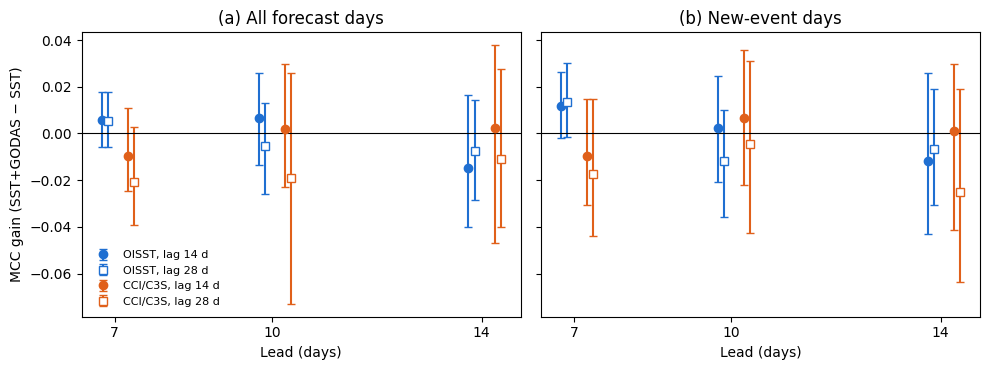

In [12]:
# [9] figure: gain of SST + GODAS over SST-only
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
style = {'OISST': ('#1f6fd1', -0.25), 'CCI': ('#e0601a', 0.25)}
for j, (g, lo, hi, title) in enumerate((('gain', 'lo', 'hi', '(a) All forecast days'),
                                         ('gain_new', 'lo_new', 'hi_new', '(b) New-event days'))):
    for name, (col, dx) in style.items():
        for lag, mk, fill in ((LAGS[0], 'o', col), (LAGS[1], 's', 'white')):
            r = RES[(RES['product'] == name) & (RES.lag == lag)]
            x = r.lead + dx + (0 if lag == LAGS[0] else 0.12)
            ax[j].errorbar(x, r[g], yerr=[r[g] - r[lo], r[hi] - r[g]], fmt=mk, color=col, mfc=fill,
                           capsize=3, label=f'{"CCI/C3S" if name == "CCI" else name}, lag {lag} d')
    ax[j].axhline(0, color='k', lw=0.8); ax[j].set_xticks(LEADS); ax[j].set_xlabel('Lead (days)'); ax[j].set_title(title)
ax[0].set_ylabel('MCC gain (SST+GODAS − SST)'); ax[0].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(f'{FIG}/fig_wp6_godas_gain.png', dpi=300); plt.show()